# Batalha → Serra do Facão

Carga constante; dois cenários por mês; discretização ajustável. Execute **Ambiente de execução → Executar tudo**.

## 1. Instalação e bibliotecas

In [1]:
import importlib.util, subprocess, sys
pacotes = ["pyscipopt", "numpy", "matplotlib", "pandas"]
faltantes = [p for p in pacotes if importlib.util.find_spec(p) is None]
if faltantes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyscipopt import Model, quicksum
from IPython.display import display

## 2. Parâmetros

Edite `CARGA`, `NR_DISC`, `AFL_MAX` e `AFL_MIN`. Em cada cenário, as duas UHEs recebem seus respectivos máximos ou mínimos. Cada cenário tem 50% de probabilidade.

In [2]:
# 1. DADOS: ordem das UHEs = [Batalha, Serra do Facão].
MESES = ["Setembro", "Outubro", "Novembro"]
CARGA = 250.0                 # Mesma carga nos três meses, em MW médios.
NR_DISC = 24                  # Níveis por UHE: 24 x 24 = 576 pares de volumes.
CENARIO_TRAJETORIA = [1, 1, 1] # 0 = máximo; 1 = mínimo, em cada mês.
MOSTRAR_GRAFICOS = True

HORAS = 30 * 24               # Mês padronizado de 30 dias, inclusive outubro.
FATOR_VOLUME = HORAS * 3600 / 1_000_000
VMIN = np.array([430.049988, 1752.0])
VMAX = np.array([1781.609985, 5199.0])
VI_INICIAL = VMIN + np.array([0.397, 0.502]) * (VMAX - VMIN)

# Produtibilidade constante. Serra usa o coeficiente equivalente do print.
# Dividir pelo fator converte MW/(m³/s) para MW médios por hm³ mensal.
ro = np.array([0.009025 * (37.70 - 1.20), 0.6157]) / FATOR_VOLUME
ENGOL = np.array([147.02, 313.0]) * FATOR_VOLUME
GTMAX1, GTMAX2 = 10.0, 17.0    # BBF Baliza e ERB Candeias, em MW.
CT1, CT2 = 882.76 * HORAS, 118.93 * HORAS
CDEF = 4000.0 * HORAS         # Custos em R$/MW médio no mês.
ESCALA_CUSTO = 1_000_000      # O solver trabalha em R$ milhões para evitar números muito grandes.

# Vazões LOCAIS em m³/s: linhas = meses; colunas = Batalha e Serra.
# Serra: máximo e mínimo dos três valores mensais fornecidos nos prints.
# São extremos do conjunto utilizado, não extremos de todo o histórico.
AFL_MAX = np.array([[30., 70.], [35., 93.], [40., 176.]])
AFL_MIN = np.array([[20., 24.], [25., 29.], [30., 20.]])
# Há apenas DOIS cenários conjuntos: ambas no máximo ou ambas no mínimo.
# Cada cenário tem 50%; entre meses, assume-se independência.
CENARIOS = [AFL_MAX * FATOR_VOLUME, AFL_MIN * FATOR_VOLUME]

# Hipóteses: transferência integral no mesmo mês; produtibilidade fixa;
# sem evaporação ou vazão mínima obrigatória; custo futuro terminal zero.

## 3. Despacho mensal

A Serra recebe a afluência local mais a água turbinada e vertida pela Batalha. Os pesos interpolam o custo futuro entre os pontos da grade.

In [3]:
# 2. DESPACHO: mesma estrutura do código de uma UHE, com dois balanços.
def despacho_hidrotermico(VI, AFL, estados=None, custos_futuros=None):
    modelo = Model("despacho_hidrotermico")
    modelo.hideOutput()
    modelo.setRealParam("numerics/dualfeastol", 1e-9)  # Preserva a pequena penalização do vertimento.

    # Volumes finais, turbinados e vertidos, em hm³.
    vf = [modelo.addVar(f"vf{i+1}", lb=float(VMIN[i]), ub=float(VMAX[i])) for i in range(2)]
    vt = [modelo.addVar(f"vt{i+1}", lb=0, ub=float(ENGOL[i])) for i in range(2)]
    vv = [modelo.addVar(f"vv{i+1}", lb=0) for i in range(2)]
    gt1 = modelo.addVar("gt1", lb=0, ub=GTMAX1)
    gt2 = modelo.addVar("gt2", lb=0, ub=GTMAX2)
    deficit = modelo.addVar("def", lb=0)
    alpha = modelo.addVar("alpha", lb=0)  # Custo futuro interno em R$ milhões.

    # Batalha recebe sua afluência local.
    modelo.addCons(vf[0] == float(VI[0] + AFL[0]) - vt[0] - vv[0])
    # Serra recebe sua afluência local + turbinamento e vertimento de Batalha.
    modelo.addCons(vf[1] == float(VI[1] + AFL[1]) + vt[0] + vv[0] - vt[1] - vv[1])
    modelo.addCons(float(ro[0])*vt[0] + float(ro[1])*vt[1] + gt1 + gt2 + deficit == CARGA)
    modelo.addCons(float(ro[1])*vt[1] <= 212.58)  # Potência nominal da Serra.

    if custos_futuros is None:
        modelo.addCons(alpha == 0)  # Último mês ou despacho isolado.
    else:
        # Interpola o custo futuro nos pares de volumes da grade.
        # Os pesos são escolhidos pelo solver; NÃO são probabilidades de AFL.
        # A soma é 1 e a combinação dos pontos deve coincidir com (vf1, vf2).
        # Cada peso multiplica um PAR de volumes e seu respectivo custo.
        pesos = [modelo.addVar(lb=0) for _ in estados]
        modelo.addCons(quicksum(pesos) == 1)
        for i in range(2):
            modelo.addCons(vf[i] == quicksum(float(v[i])*p for v, p in zip(estados, pesos)))
        modelo.addCons(alpha == quicksum(float(c/ESCALA_CUSTO)*p for c, p in zip(custos_futuros, pesos)))
        # Minimizar escolhe a combinação de menor custo: a mesma interpolação
        # convexa representada pelos planos da versão anterior.

    custo_imediato = CT1*gt1 + CT2*gt2 + CDEF*deficit + 0.01*quicksum(vv)
    modelo.setObjective(custo_imediato/ESCALA_CUSTO + alpha, sense="minimize")
    modelo.optimize()
    if modelo.getStatus() != "optimal":
        raise RuntimeError(f"Solução não ótima: {modelo.getStatus()}")

    # Converte todos os custos de saída de volta para reais.
    resultado = {"fob":modelo.getObjVal()*ESCALA_CUSTO, "ci":modelo.getVal(custo_imediato),
        "alpha":modelo.getVal(alpha)*ESCALA_CUSTO, "vf":np.array([modelo.getVal(v) for v in vf]),
        "vt":np.array([modelo.getVal(v) for v in vt]), "vv":np.array([modelo.getVal(v) for v in vv]),
        "gt1":modelo.getVal(gt1), "gt2":modelo.getVal(gt2), "def":modelo.getVal(deficit)}
    modelo.freeProb()
    return resultado

## 4. Planejamento

Resolve de trás para frente. Em cada par de volumes, guarda a média dos custos dos cenários máximo e mínimo.

In [4]:
# 3. PLANEJAMENTO: do último mês para o primeiro.
def planejamento():
    # Checagens básicas das entradas editáveis.
    if not isinstance(NR_DISC, int) or NR_DISC < 2:
        raise ValueError("NR_DISC deve ser um inteiro >= 2.")
    if any(a.shape != (len(MESES), 2) for a in [AFL_MAX, AFL_MIN]):
        raise ValueError("Informe uma linha de afluências para cada mês.")
    if not np.isfinite(CARGA) or CARGA < 0 or not np.all(np.isfinite([AFL_MAX, AFL_MIN])):
        raise ValueError("Carga e afluências devem ser finitas.")
    if np.any(AFL_MIN < 0) or np.any(AFL_MAX < AFL_MIN):
        raise ValueError("As afluências devem respeitar 0 <= mínima <= máxima.")
    if len(CENARIO_TRAJETORIA) != len(MESES) or any(s not in [0, 1] for s in CENARIO_TRAJETORIA):
        raise ValueError("Escolha 0 ou 1 para cada mês da trajetória.")

    # Cada estado é um par: (volume inicial de Batalha, volume inicial de Serra).
    grades = [np.linspace(VMIN[i], VMAX[i], NR_DISC) for i in range(2)]
    estados = np.array(list(product(*grades)))
    curvas = [None] * (len(MESES) + 1)  # Última posição: custo futuro zero.
    for t in range(len(MESES)-1, -1, -1):
        custos = []
        for VI in estados:
            resultados = []
            for cenario in CENARIOS:  # Resolve máximo e mínimo separadamente.
                r = despacho_hidrotermico(VI, cenario[t], estados, curvas[t+1])
                resultados.append(r["fob"])
            custos.append(sum(resultados)/2)  # Média dos DOIS custos totais.
        curvas[t] = np.array(custos)
        print(f"{MESES[t]}: {len(estados)} pares de volumes e dois cenários.")
    return grades, estados, curvas

## 5. Operação ao longo dos meses

O volume final de cada usina passa a ser seu volume inicial no mês seguinte.

In [5]:
# 4. TRAJETÓRIA: avança no tempo usando a política calculada.
def simular(estados, curvas, considerar_futuro=True):
    VI, trajetoria = VI_INICIAL.copy(), []
    for t, mes in enumerate(MESES):
        AFL = CENARIOS[CENARIO_TRAJETORIA[t]][t]
        futuro = curvas[t+1] if considerar_futuro else None
        r = despacho_hidrotermico(VI, AFL, estados, futuro)
        trajetoria.append({"mes":mes, "VI":VI.copy(), "AFL":AFL.copy(), **r})
        VI = r["vf"].copy()  # Volume final deste mês = inicial do próximo.
    return trajetoria


def tabela_resultados(trajetoria):
    # Cada linha resume um mês. Não somar FOB: repetiria custos futuros.
    return pd.DataFrame([{"Mês":r["mes"], "Batalha (MWm)":ro[0]*r["vt"][0],
        "Serra (MWm)":ro[1]*r["vt"][1], "Baliza (MWm)":r["gt1"],
        "Candeias (MWm)":r["gt2"], "Déficit (MWm)":r["def"],
        "VF Batalha (hm³)":r["vf"][0], "VF Serra (hm³)":r["vf"][1],
        "Custo imediato (R$ mi)":r["ci"]/1e6} for r in trajetoria])

## 6. Gráficos

In [6]:
# 5. GRÁFICOS: geração, armazenamento e custo por par de volumes.
def graficos(grades, curvas, planejada, isolada):
    nomes = ["Batalha", "Serra do Facão", "BBF Baliza", "ERB Candeias", "Déficit"]
    cores = ["#205b8d", "#79a4bf", "#bb8531", "#917049", "#914a70"]
    fig, eixos = plt.subplots(1, 2, figsize=(12, 5), sharey=True, layout="constrained")
    for ax, traj, titulo in zip(eixos, [planejada, isolada], ["Com custo futuro", "Despachos isolados"]):
        valores = np.array([[ro[0]*r["vt"][0], ro[1]*r["vt"][1],
                            r["gt1"], r["gt2"], max(0,r["def"])] for r in traj])
        base = np.zeros(len(MESES))
        for j, nome in enumerate(nomes):
            barras = ax.bar(MESES, valores[:,j], bottom=base, color=cores[j], label=nome)
            # Escreve a contribuição em MW médios no centro de cada segmento.
            labels = [f"{v:.1f}" if v > 0.05 else "" for v in valores[:,j]]
            ax.bar_label(barras, labels=labels, label_type="center", fontsize=9,
                         color="white" if j in [0,3,4] else "black")
            base += valores[:,j]
        ax.axhline(CARGA, color="black", ls="--", lw=1, label="Carga")
        ax.set(title=titulo, ylabel="Geração e déficit (MW médios)", ylim=(0,CARGA*1.1))
        ax.grid(axis="y", alpha=.15)
    fig.legend(*eixos[0].get_legend_handles_labels(), loc="upper center",
               bbox_to_anchor=(.5,1.08), ncol=6, fontsize=9)
    plt.show()

    fig, eixos = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    for i, ax in enumerate(eixos):
        for traj, nome, estilo in [(planejada,"Com custo futuro","o-"),(isolada,"Isolados","s--")]:
            volumes = np.array([VI_INICIAL[i]] + [r["vf"][i] for r in traj])
            percentual = 100*(volumes-VMIN[i])/(VMAX[i]-VMIN[i])
            ax.plot(["Inicial"]+MESES, percentual, estilo, label=nome)
        ax.set(title=nomes[i], ylabel="Volume útil armazenado (%)", ylim=(0,100))
        ax.grid(alpha=.2)
        ax.legend()
    plt.show()

    # Liga os custos calculados na grade para visualizar a superfície.
    # A interpolação do solver é feita pelos pesos, não por este gráfico.
    x, y = np.meshgrid(np.linspace(0,100,NR_DISC), np.linspace(0,100,NR_DISC), indexing="ij")
    for inicio in range(0, len(MESES), 3):
        n = min(3, len(MESES)-inicio)
        fig = plt.figure(figsize=(5.2*n, 5), layout="constrained")
        for j in range(n):
            t = inicio+j
            ax = fig.add_subplot(1,n,j+1,projection="3d")
            ax.plot_surface(x, y, curvas[t].reshape(NR_DISC,NR_DISC)/1e6, color="#79a4bf")
            ax.set(title=f"Custo desde {MESES[t]}", xlabel="VI Batalha (% útil)",
                   ylabel="VI Serra (% útil)", zlabel="Custo (R$ milhões)")
        plt.show()

## 7. Resultados

A média pertence ao planejamento. A trajetória usa os cenários escolhidos em `CENARIO_TRAJETORIA`.

In [7]:
grades, estados, curvas = planejamento()
planejada = simular(estados, curvas)
isolada = simular(estados, curvas, considerar_futuro=False)

# Resolve os dois cenários no volume inicial real, com o custo futuro.
custos_iniciais = []
for cenario in CENARIOS:
    resultado = despacho_hidrotermico(VI_INICIAL, cenario[0], estados, curvas[1])
    custos_iniciais.append(resultado["fob"])
display(pd.DataFrame({"Cenário":["Máximo", "Mínimo"], "Custo total (R$ mi)":np.array(custos_iniciais)/1e6}).round(3))
print(f"Média dos dois custos: R$ {sum(custos_iniciais)/2:,.2f}")

print("TRAJETÓRIA COM CUSTO FUTURO")
display(tabela_resultados(planejada).round(2))
print("TRAJETÓRIA COM DESPACHOS ISOLADOS")
display(tabela_resultados(isolada).round(2))
# Soma apenas custos imediatos: FOB inclui custos dos meses seguintes.
for nome, traj in [("Planejada", planejada),("Isolada", isolada)]:
    print(f"{nome} — custo realizado: R$ {sum(r['ci'] for r in traj):,.2f}")

Novembro: 576 pares de volumes e dois cenários.
Outubro: 576 pares de volumes e dois cenários.
Setembro: 576 pares de volumes e dois cenários.


,Cenário,Custo total (R$ mi)
0,Máximo,17.951
1,Mínimo,20.309


Média dos dois custos: R$ 19,130,005.17
TRAJETÓRIA COM CUSTO FUTURO


,Mês,Batalha (MWm),Serra (MWm),Baliza (MWm),Candeias (MWm),Déficit (MWm),VF Batalha (hm³),VF Serra (hm³),Custo imediato (R$ mi)
0,Setembro,30.29,192.71,10.00,17.0,0.0,780.15,2971.61,7.81
1,Outubro,30.32,192.71,9.96,17.0,0.0,606.34,2474.10,7.79
2,Novembro,32.29,192.71,8.00,17.0,0.0,430.05,1968.69,6.54


TRAJETÓRIA COM DESPACHOS ISOLADOS


,Mês,Batalha (MWm),Serra (MWm),Baliza (MWm),Candeias (MWm),Déficit (MWm),VF Batalha (hm³),VF Serra (hm³),Custo imediato (R$ mi)
0,Setembro,48.43,192.71,0.0,8.86,0.0,637.38,3114.38,0.76
1,Outubro,34.58,192.71,5.7,17.00,0.0,430.05,2650.39,5.08
2,Novembro,9.88,192.71,10.0,17.00,20.4,430.05,1968.69,66.57


Planejada — custo realizado: R$ 22,138,227.68
Isolada — custo realizado: R$ 72,411,194.19


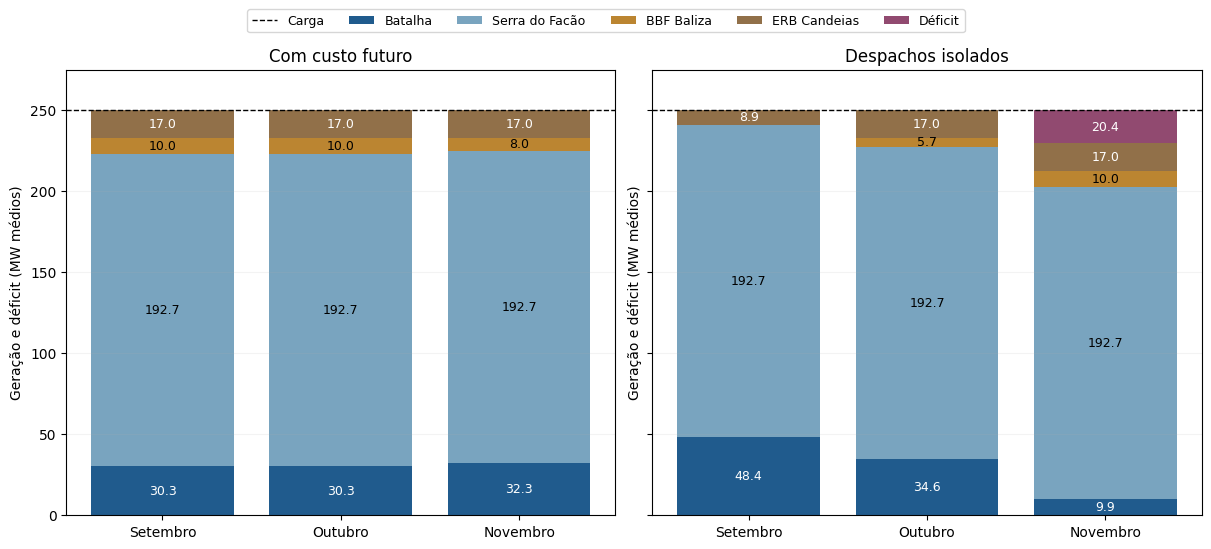

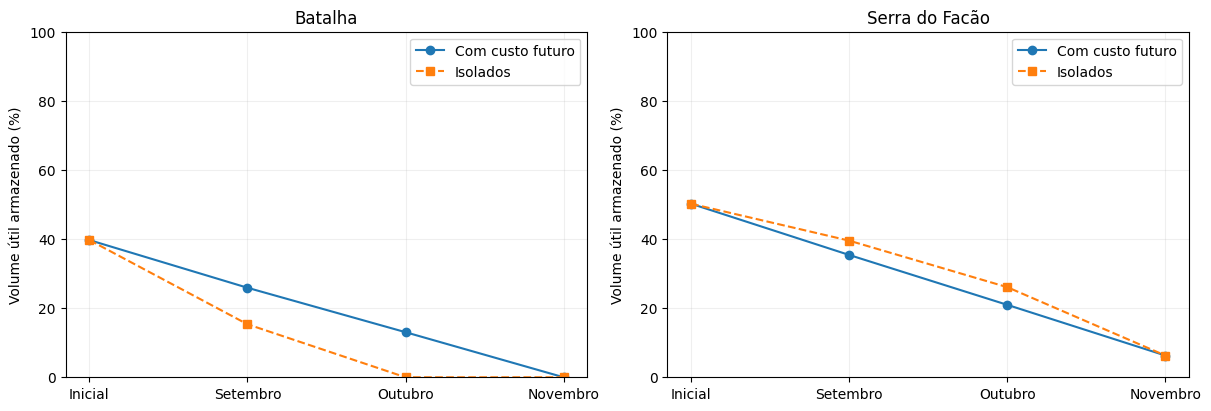

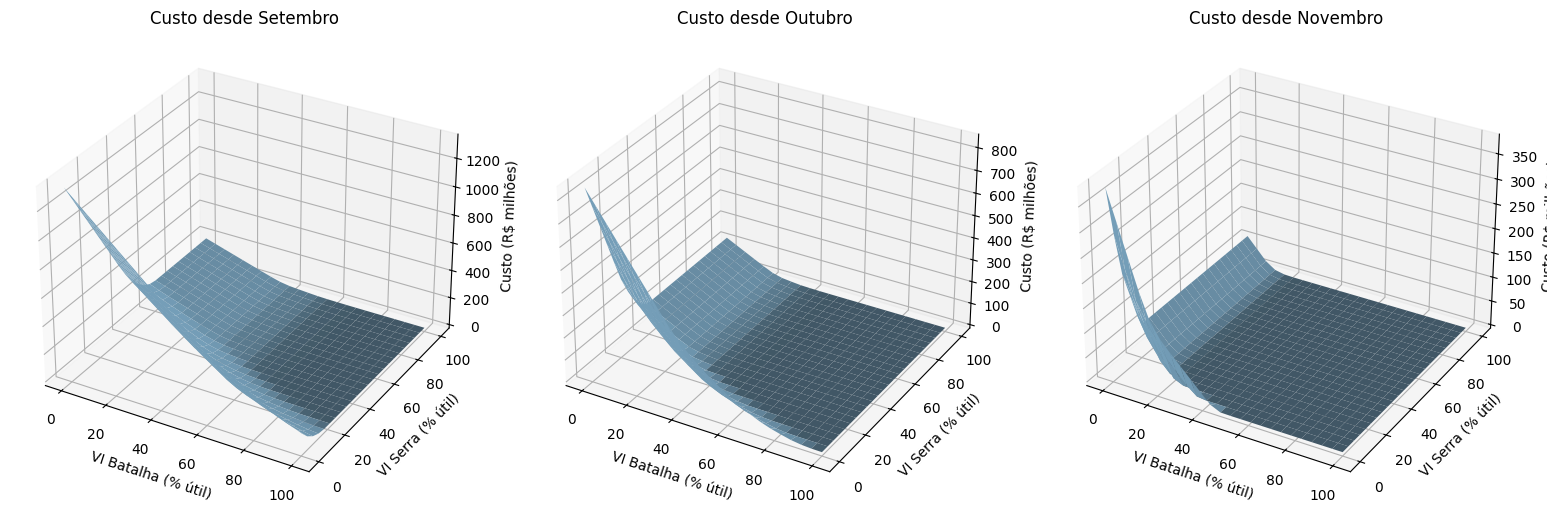

In [8]:
if MOSTRAR_GRAFICOS:
    graficos(grades, curvas, planejada, isolada)

Superfícies: custos calculados na grade. A interpolação do solver usa os pesos; `NR_DISC` controla a aproximação. Barras: contribuições positivas em MW médios.

Hipóteses: meses de 30 dias, produtividade fixa, transferência integral no mesmo mês e custo terminal zero. Despachos isolados podem ter alocações hidráulicas equivalentes naquele mês, com consequências futuras diferentes.